# MethaneSET · plume bank

Column enhancements built from WRF-LES simulations, projected onto observation geometries. This tutorial queries one map, checks how it scales to any emission rate and reprojects a raw 3D cube, which is how new geometries are generated.

In [1]:
HF_TOKEN = ""  #@param {type:"string"}

# Anonymous Hugging Face reads share the rate limit of the whole Colab fleet. With a free
# account token pasted above the limit is yours, and the notebook stops hitting 429.
# Create one at https://huggingface.co/settings/tokens (read access is enough).
if HF_TOKEN:
    import os
    os.environ["HF_TOKEN"] = HF_TOKEN
    try:
        from huggingface_hub import login
        login(HF_TOKEN, add_to_git_credential=False)
        print("Using your Hugging Face token.")
    except Exception as exc:
        print("Token not accepted:", exc)

In [2]:
# Setup
import os, urllib.request
if not os.path.exists("common.py"):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/IPL-UV/taco-methaneset/main/methaneset-codes/notebooks/common.py",
        "common.py")
try:
    import tacoreader, rasterio
except ImportError:
    %pip install "tacoreader>=2.4,<3" rasterio matplotlib pandas pyarrow scipy scikit-image
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
warnings.filterwarnings("ignore", category=rasterio.errors.NotGeoreferencedWarning)
import common as C
C.style()
import matplotlib as _mpl
_mpl.rcParams["figure.dpi"] = _mpl.rcParams["savefig.dpi"] = 70
C.versions()
print("dataset version", C.dataset_version("methaneset-bank"))

tacoreader 2.4.21
rasterio   1.4.4
numpy      2.4.6
torch      2.7.0+cu126
colab      False
[common] methaneset-bank: local
dataset version 1.0.0


In [3]:
def project(heights, vza=0.0, vaa=0.0):
    """Column map for a sun at (sza, raa) and a sensor at (vza, vaa), all in degrees.

    Each level moves heights[k] * tan(angle) towards azimuth + 180, bilinearly split so
    the mass is conserved. With vza = 0 the view path keeps the unshifted column, which
    is what the stored maps do. Returns the map and the (row, col) of its [0, 0] pixel in
    the volume frame."""
    ny, nx = vol.shape[1:]
    a_s = 1.0 / np.cos(np.radians(sza))
    a_v = 1.0 / np.cos(np.radians(vza))

    def shift(angle, azimuth):
        s = heights * np.tan(np.radians(angle)) / px
        a = np.radians(azimuth + 180.0)
        return s * np.cos(a), s * np.sin(a)

    dx, dy = shift(sza, raa)
    dxv, dyv = shift(vza, vaa) if vza else (None, None)

    xs = [0, int(np.floor(dx.min())), int(np.floor(dx.max())) + 1]
    ys = [0, int(np.floor(dy.min())), int(np.floor(dy.max())) + 1]
    if vza:
        xs += [int(np.floor(dxv.min())), int(np.floor(dxv.max())) + 1]
        ys += [int(np.floor(dyv.min())), int(np.floor(dyv.max())) + 1]
    x_lo, x_hi, y_lo, y_hi = min(xs), max(xs), min(ys), max(ys)

    sol = np.zeros((ny + y_hi - y_lo, nx + x_hi - x_lo))
    up = np.zeros_like(sol)

    def splat(dst, ddx, ddy, L):
        ix, iy = int(np.floor(ddx)), int(np.floor(ddy))
        fx, fy = ddx - ix, ddy - iy
        r, c = iy - y_lo, ix - x_lo
        dst[r:r+ny, c:c+nx]         += (1 - fx) * (1 - fy) * L
        dst[r:r+ny, c+1:c+1+nx]     += fx * (1 - fy) * L
        dst[r+1:r+1+ny, c:c+nx]     += (1 - fx) * fy * L
        dst[r+1:r+1+ny, c+1:c+1+nx] += fx * fy * L

    for k in range(vol.shape[0]):
        splat(sol, dx[k], dy[k], vol[k])
        if vza:
            splat(up, dxv[k], dyv[k], vol[k])
        else:
            up[-y_lo:-y_lo+ny, -x_lo:-x_lo+nx] += vol[k]
    return (a_s * sol + a_v * up) / (a_s + a_v), sol, dx, dy, (y_lo, x_lo)

In [4]:
def place(a, y_lo, x_lo, H, W):
    """Put a projected map on a common canvas: canvas row 0 is volume row -y_lo."""
    out = np.zeros((H, W))
    out[-y_lo:-y_lo + a.shape[0], -x_lo:-x_lo + a.shape[1]] = a
    return out


def centroid(a):
    """Mass centroid in pixels."""
    rr, cc = np.indices(a.shape)
    t = a.sum()
    return (rr * a).sum() / t, (cc * a).sum() / t


def mark_source(ax, en, row, wind=True):
    """Cross on the source pixel, wind arrow and the four edge labels."""
    sc = int(row["array:source_col"]), int(row["array:source_row"])
    h, w = en.shape
    ax.scatter([sc[0]], [sc[1]], c=C.PALETTE["ink"], s=30, marker="x")
    if wind:
        ax.annotate("", xy=(sc[0] + 0.12 * w, sc[1]), xytext=(sc[0] - 0.05 * w, sc[1]),
                    arrowprops=dict(arrowstyle="->", color=C.PALETTE["ink"], lw=1.5))
        ax.text(sc[0] + 0.13 * w, sc[1], "wind", fontsize=7, va="center", color=C.PALETTE["ink"])
    for txt, x, y, rot, ha, va in (("upwind", 0.02, 0.5, 90, "left", "center"),
                                   ("downwind", 0.98, 0.5, 90, "right", "center"),
                                   ("bottom", 0.5, 0.02, 0, "center", "bottom"),
                                   ("top", 0.5, 0.98, 0, "center", "top")):
        ax.text(x, y, txt, transform=ax.transAxes, rotation=rot, fontsize=7,
                color=C.PALETTE["muted"], ha=ha, va=va)

## The catalog

238,545 maps from 1,647 cubes. A map is identified by emitter, wind speed, solar zenith (SZA) and relative azimuth (RAA); the enhancement is stored at a reference rate of 3,000 kg/h.

In [5]:
bank = C.load("methaneset-bank")
df = bank.data.to_pandas()
print(f"{df.shape[0]:,} maps | {df['methane:plume_uid'].nunique()} physical plumes | {df['methane:wind_speed'].nunique()} wind speeds")
print("SZA nodes:", df['sun:sza'].nunique(), "| RAA nodes:", df['sun:raa'].nunique(),
      "| total geometry nodes:", df[['sun:sza','sun:raa']].drop_duplicates().shape[0])
print("Emitters:", sorted(df['methane:emitter'].unique())[:6], "...")

# One-line descriptions taken from pipeline/bank/core/schema.py
DESC = {
    "methane:": "plume identity: emitter, wind speed, snapshot, scale factor, peak and mean height",
    "sun:": "solar geometry: zenith angle (SZA) and relative azimuth (RAA)",
    "edge:": "maxima on the four edges of the canvas and the downwind slope",
    "array:": "GeoTIFF layout: size, source pixel location and canvas growth per side",
    "qa:": "zero-threshold control: IME before/after and foreign-mass fraction",
}
pd.DataFrame({"namespace": list(DESC.keys()), "what it contains": list(DESC.values())})

[common] methaneset-bank: local


238,545 maps | 279 physical plumes | 11 wind speeds
SZA nodes: 17 | RAA nodes: 692 | total geometry nodes: 855
Emitters: ['a1', 'a2', 'a3', 'a4', 'a5', 'a6'] ...


,namespace,what it contains
0,methane:,"plume identity: emitter, wind speed, snapshot,..."
1,sun:,solar geometry: zenith angle (SZA) and relativ...
2,edge:,maxima on the four edges of the canvas and the...
3,array:,"GeoTIFF layout: size, source pixel location an..."
4,qa:,zero-threshold control: IME before/after and f...


## A query

Any geometry resolves to the nearest stored node. The angular distance tells how far the match is; a few degrees is the normal case.

In [6]:
# Example query
sza_q, raa_q, wind_q = 61.0, 5.0, 3.2
idx, ang_dist, wind_err = C.bank_query(df, sza_q, raa_q, wind_q, k=1)
row = df.iloc[idx]
print(f"Query: SZA {sza_q} deg, RAA {raa_q} deg, wind {wind_q} m/s")
print(f"Nearest index: {idx}")
print(f"Angular distance: {ang_dist:.2f} deg")
print(f"Wind error: {wind_err:.2f} m/s")
print(f"Matched map: {row['id']}")

Query: SZA 61.0 deg, RAA 5.0 deg, wind 3.2 m/s
Nearest index: 197789
Angular distance: 0.74 deg
Wind error: 0.20 m/s
Matched map: p8_w03.0_s098_sza61.2_raa005.7


In [7]:
en = C.read(bank.read(int(row.name)), bands=1)
peak = np.nanmax(en)
print(f"Map shape: {en.shape} | peak {peak:.0f} ppb | mean {np.nanmean(en):.1f} ppb")
print(f"Source pixel: col {int(row['array:source_col'])}, row {int(row['array:source_row'])}")

Map shape: (68, 104) | peak 2111 ppb | mean 24.5 ppb
Source pixel: col 18, row 39


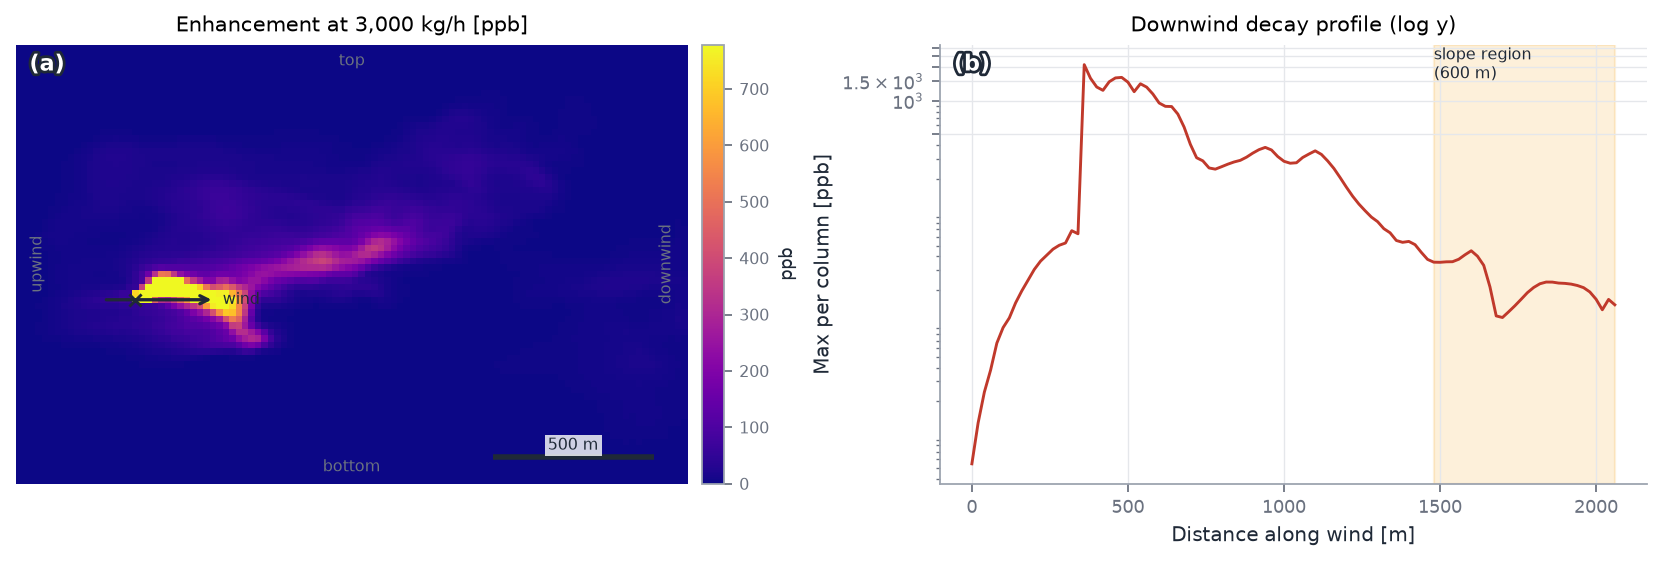

In [8]:
fig, axes = C.panels(2, dpi=C.DPI["hero"], kind="image", w=C.FIGW)

C.imshow_layer(axes[0], en, kind="enh", title="Enhancement at 3,000 kg/h [ppb]",
               label="ppb", px_m=C.PIXEL_M["bank"])
mark_source(axes[0], en, row)
C.panel_label(axes[0], "a")

ax = axes[1]
max_col = np.nanmax(en, axis=0)
x_m = np.arange(len(max_col)) * C.PIXEL_M["bank"]
ax.plot(x_m, max_col, color=C.PALETTE["ch4"], lw=1.3)
ax.set_yscale("log")
C.ax_plot(ax)
ax.set_xlabel("Distance along wind [m]")
ax.set_ylabel("Max per column [ppb]")
ax.set_title("Downwind decay profile (log y)")
last_m = 600
n_last = int(np.ceil(last_m / C.PIXEL_M["bank"]))
ax.axvspan(x_m[-n_last], x_m[-1], color=C.PALETTE["sun"], alpha=0.15)
ax.text(x_m[-n_last], ax.get_ylim()[1] * 0.5, f"slope region\n({last_m} m)",
        fontsize=7, color=C.PALETTE["ink"])
C.panel_label(ax, "b")
plt.show()

## Scaling to another emission rate

Q = 10,000 kg/h -> peak 7035 ppb
Linearity holds in the enhancement, not in the radiance: factor 3.33
IME kept after the zero-threshold: 99.908%


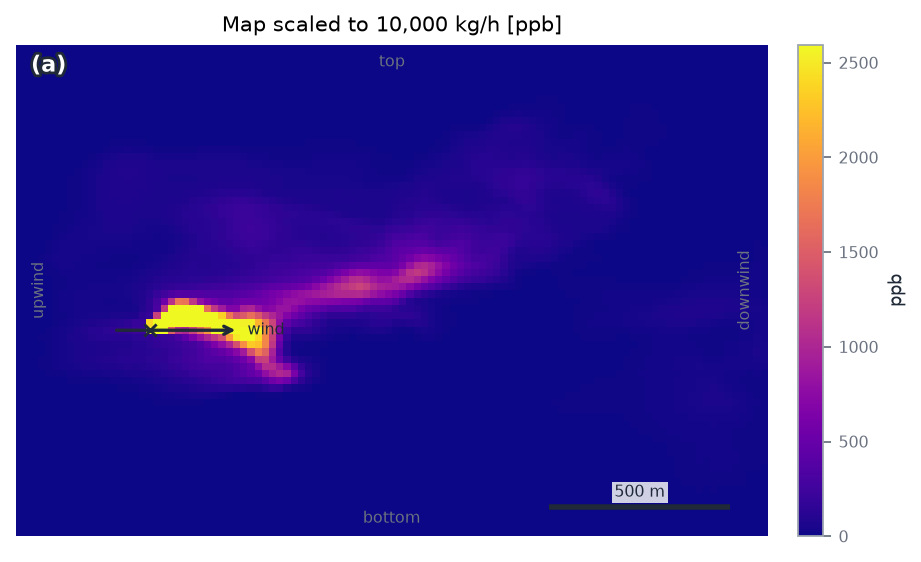

In [9]:
Q = 10_000
en_q = en * (Q / 3_000.0)
print(f"Q = {Q:,} kg/h -> peak {np.nanmax(en_q):.0f} ppb")
print(f"Linearity holds in the enhancement, not in the radiance: factor {Q/3000:.2f}")
print(f"IME kept after the zero-threshold: {row['qa:ime_after'] / row['qa:ime_before']:.3%}")

fig, axes = C.panels(1, dpi=C.DPI["hero"], kind="image", w=C.FIGW)
C.imshow_layer(axes[0], en_q, kind="enh", title=f"Map scaled to {Q:,} kg/h [ppb]",
               label="ppb", px_m=C.PIXEL_M["bank"])
mark_source(axes[0], en_q, row)
C.panel_label(axes[0], "a")

## Reprojecting a raw cube

This is where new geometries come from. The volume is read level by level, each level is shifted by `height * tan(angle)` and the mass is split bilinearly, so the column map conserves the mass of the cube. The solar weight is `1 / cos(SZA)` and the view weight `1 / cos(VZA)`.

In [10]:
les = C.load("methaneset-bank-les")
dfl = les.data.to_pandas()
# example LES node: first emitter at 3 m/s (the LES cubes carry no sun: columns)
_ok = dfl[dfl["criteria:pasa"]] if "criteria:pasa" in dfl.columns else dfl
ok = _ok.query("`methane:wind_speed` == 3")
lrow = ok.iloc[0] if len(ok) else _ok.iloc[0]

IME = float(lrow["methane:ime_ppb_px"])
L = float(lrow["plume:length_downwind_m"])
U_eff = float(lrow["methane:wind_speed"])

mol = IME * 3.6055e5 * 400 / 1e9
kg = mol * 16.04 / 1000.0
Q_est = kg * U_eff / L * 3600  # kg/s -> kg/h

print(f"Plume: {lrow['methane:emitter']}, wind {U_eff} m/s, length {L:.0f} m")
print(f"IME = {IME:,.0f} ppb px")
print(f"Moles = {mol:,.0f} mol")
print(f"Mass = {kg:,.0f} kg")
print(f"Estimated flux Q = IME * U_eff / L = {Q_est:,.0f} kg/h")
print(f"Ratio to bank reference 3,000 kg/h: {Q_est/3000:.2f}")
print(f"U_eff is the effective wind; it carries most of the method uncertainty.")

[common] methaneset-bank-les: local
Plume: a1, wind 3.0 m/s, length 1780 m
IME = 208,866 ppb px
Moles = 30,123 mol
Mass = 483 kg
Estimated flux Q = IME * U_eff / L = 2,932 kg/h
Ratio to bank reference 3,000 kg/h: 0.98
U_eff is the effective wind; it carries most of the method uncertainty.


In [11]:
lrow = dfl.iloc[0]
cube = C.read(les.read(int(lrow.name)), nan_nodata=False)   # (49, H, W) in ppb
z = np.asarray(lrow["grid:level_heights_m"], dtype="float32")
col = cube.sum(axis=0)
print(f"Cube: {cube.shape} | levels {z.min():.0f}-{z.max():.0f} m")

Cube: (49, 90, 120) | levels 10-991 m


In [12]:
# One stored map that also has its raw cube: emitter p6, wind 3 m/s, SZA near 61 deg
q = df.query("`methane:emitter` == 'p6' and `methane:wind_speed` == 3")
brow = q.iloc[(q["sun:sza"] - 61.2).abs().argsort()[:1]].iloc[0]
stored = C.read(bank.read(int(brow.name)), bands=1)

ql = dfl.query("`methane:emitter` == 'p6' and `methane:wind_speed` == 3")
lrow = ql.iloc[(ql["methane:snapshot_index"] - float(brow["methane:snapshot_index"])).abs().argsort()[:1]].iloc[0]

RELAX, px = 5, 20.0
vol = C.read(les.read(int(lrow.name)), nan_nodata=False)[:, RELAX:-RELAX, RELAX:-RELAX]
z = np.asarray(lrow["grid:level_heights_m"], dtype="float32")
sza, raa = float(brow["sun:sza"]), float(brow["sun:raa"])
print(f"Emitter p6, 3 m/s | SZA {sza:.1f}, RAA {raa:.1f} | volume {vol.shape}")

Emitter p6, 3 m/s | SZA 61.2, RAA 354.3 | volume (49, 80, 110)


In [13]:
comb, _, dx, dy, _ = project(z)      # the stored bank is nadir: the sun is the only shift
print(f"Stored map {stored.shape} (pipeline) vs reprojected {comb.shape} (this step)")
print(f"Peak: stored {stored.max():.0f} ppb | reprojected {comb.max():.0f} ppb")

Stored map (74, 116) (pipeline) vs reprojected (89, 200) (this step)
Peak: stored 2198 ppb | reprojected 1713 ppb


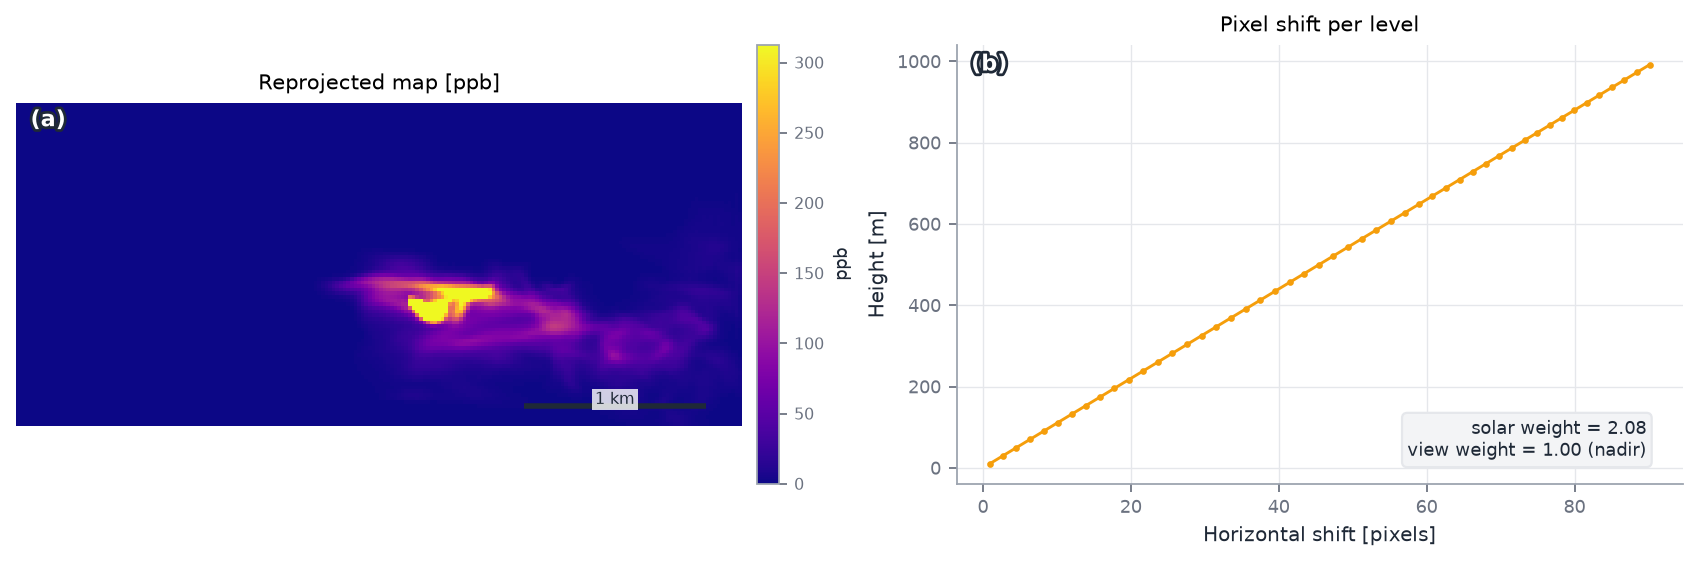

In [14]:
fig, axes = C.panels(2, dpi=C.DPI["hero"], kind="image", w=C.FIGW)
C.imshow_layer(axes[0], np.flipud(comb), kind="enh", title="Reprojected map [ppb]",
               label="ppb", px_m=C.PIXEL_M["bank"])
C.panel_label(axes[0], "a")

ax = axes[1]
ax.plot(np.hypot(dx, dy), z, marker="o", ms=2, color=C.PALETTE["sun"])
C.ax_plot(ax)
ax.set_xlabel("Horizontal shift [pixels]")
ax.set_ylabel("Height [m]")
ax.set_title("Pixel shift per level")
ax.text(0.95, 0.05, f"solar weight = {1 / np.cos(np.radians(sza)):.2f}\nview weight = 1.00 (nadir)",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=8,
        color=C.PALETTE["ink"],
        bbox=dict(boxstyle="round", facecolor=C.PALETTE["light"], edgecolor=C.PALETTE["grid"]))
C.panel_label(ax, "b")
plt.show()